In [171]:
import pandas as pd

df = pd.read_csv("../data/master.csv", index_col=0, parse_dates=True)

In [172]:
df["spread"] = df["fund_rate"] - df["hibor"]
df["flow"] = df["closing_balance"].diff()
df["usd_change"] = df["usd"].pct_change()
df["volatility"] = df["usd_change"].rolling(30).std()

In [ ]:
import numpy as np

print("="*50)
print("1. Peg Stability Analysis")
print("="*50)

# Analysis of band adherence
within_band = df.usd.between(7.75, 7.85).sum()
above_band = (df.usd > 7.85).sum()
below_band = (df.usd < 7.75).sum()
total_days = len(df)
print("Band Adherence Analysis (7.75 - 7.85):")
print(f"    Days within band: {within_band} ({within_band / total_days:.2%})")
print(f"    Days above band: {above_band} ({above_band / total_days:.2%})")
print(f"    Days below band: {below_band} ({below_band / total_days:.2%})")

# Statistical summary of exchange rates
mean_rate = df['usd'].mean()
median_rate = df['usd'].median()
std_rate = df['usd'].std()
min_rate = df['usd'].min()
max_rate = df['usd'].max()
rate_range = max_rate - min_rate
print(f"\nExchange Rate Distribution:")
print(f"   Mean: {mean_rate:.4f}")
print(f"   Median: {median_rate:.4f}")
print(f"   Std Dev: {std_rate:.6f}")
print(f"   Min: {min_rate:.4f}")
print(f"   Max: {max_rate:.4f}")
print(f"   Range: {rate_range:.6f}")

# Deviation from peg center (7.80)
df['deviation_from_center'] = abs(df['usd'] - 7.80)
avg_deviation = df['deviation_from_center'].mean()
max_deviation = df['deviation_from_center'].max()
print("\nDeviation Analysis (from center 7.80):")
print(f"    Average deviation: {avg_deviation:.6f}")
print(f"    Maximum deviation: {max_deviation:.6f}")

# Volatility analysis
daily_std = df['usd_change'].std()
annualized_volatility = daily_std * np.sqrt(252)
print("\nVolatility Analysis:")
print(f"    Daily Standard Deviation: {daily_std:.2%}")
print(f"    Annualized Volatility: {annualized_volatility:.2%}")

1. Peg Stability Analysis
Band Adherence Analysis (7.75 - 7.85):
    Days within band: 4757 (93.18%)
    Days above band: 203 (3.98%)
    Days below band: 145 (2.84%)

Exchange Rate Distribution:
   Mean: 7.7844
   Median: 7.7730
   Std Dev: 0.032998
   Min: 7.7495
   Max: 7.8535
   Range: 0.104000

Deviation Analysis (from center 7.80):
    Average deviation: 0.032948
    Maximum deviation: 0.053500

Volatility Analysis:
    Daily Standard Deviation: 0.04%
    Annualized Volatility: 0.60%


In [ ]:
print("="*50)
print("2. Correlation Analysis")
print("="*50)

hibor_fed_corr = df['hibor'].corr(df['fund_rate'])
usd_spread_corr = df['usd'].corr(df['spread'])
usd_flow_corr = df['usd'].corr(df['flow'])
fed_agg_corr = df['fund_rate'].corr(df['closing_balance'])
print("Correlation Analysis:")
print(f"    Correlation between HIBOR and Federal Funds Rate: {hibor_fed_corr:.4f}")
print("       -> A high positive correlation indicates that as the Federal Funds Rate changes, HIBOR tends to move in the same direction.")
print(f"    Correlation between exchange rate and spread: {usd_spread_corr:.4f}")
print("       -> Some correlation but not very strong, suggesting the spread does not heavily influence exchange rate movements.")
print(f"    Correlation between exchange rate and flow: {usd_flow_corr:.4f}")
print("       -> Low and negative correlation indicating that changes in USD flow have minimal impact on exchange rate movements.")
print(f"    Correlation between Federal Funds Rate and HKMA Aggregate Balance: {fed_agg_corr:.4f}")
print("       -> A moderate negative correlation suggests that as the Federal Funds Rate increases, the HKMA Aggregate Balance tends to decrease, possibly due to monetary policy actions.")

2. Correlation Analysis
Correlation Analysis:
    Correlation between HIBOR and Federal Funds Rate: 0.9446
       -> A high positive correlation indicates that as the Federal Funds Rate changes, HIBOR tends to move in the same direction.
    Correlation between exchange rate and spread: 0.5268
       -> Some correlation but not very strong, suggesting the spread does not heavily influence exchange rate movements.
    Correlation between exchange rate and flow: -0.1352
       -> Low and negative correlation indicating that changes in USD flow have minimal impact on exchange rate movements.
    Correlation between Federal Funds Rate and HKMA Aggregate Balance: -0.7117
       -> A moderate negative correlation suggests that as the Federal Funds Rate increases, the HKMA Aggregate Balance tends to decrease, possibly due to monetary policy actions.


In [186]:
print("="*50)
print("3. HKMA Intervention Analysis")
print("="*50)

monetary_base_change = df.iloc[-1]['closing_balance']/df.iloc[0]["closing_balance"]
max_monetary_base_change = df['closing_balance'].max() / df.iloc[0]["closing_balance"]
print("Monetary Base Analysis:")
print(f"    Change in aggregate balance over period: {monetary_base_change:.2f}x ({(monetary_base_change - 1) * 100:,.2f}%)")
print(f"    Maximum aggregate balance: {max_monetary_base_change:.2f}x ({(max_monetary_base_change - 1) * 100:,.2f}%)")

print("\nDaily Balance Changes:")
avg_daily_flow = df['flow'].mean()
std_daily_flow = df['flow'].std()
print(f"    Average daily flow: ${avg_daily_flow:,.0f} million HKD")
print(f"    Std Dev of daily flow: ${std_daily_flow:,.0f} million HKD")

most_drain = df['flow'].min()
most_inject = df['flow'].max()
most_draining_day = df['flow'].idxmin()
most_injecting_day = df['flow'].idxmax()
significant_days = (abs(df.flow) > 1000).sum()
pct_significant = (significant_days / len(df)) * 100
significant_per_year = significant_days / ((df.index[-1] - df.index[0]).days / 365.25)
print("\nSignificant Interventions:")
print(f"    Largest single day drain: -${-most_drain:,.0f} million HKD on {most_draining_day.date()}")
print(f"    Largest single day injection: ${most_inject:,.0f} million HKD on {most_injecting_day.date()}")
print(f"    Number of days with interventions > $1 billion HKD: {significant_days} ({pct_significant:.2f}%)")
print(f"    Average significant intervention pear year: {significant_per_year:.0f} days/year")

df['flow_5d'] = df['flow'].rolling(10).sum()
max_5d_drain = df['flow_5d'].min()
max_5d_drain_date = df['flow_5d'].idxmin()
max_5d_inject = df['flow_5d'].max()
max_5d_inject_date = df['flow_5d'].idxmax()
print("\nMulti-Day Pressure (5-Day Rolling Window):")
print(f"    Largest 5-day Net Drain: -${abs(max_5d_drain):,.0f} million HKD")
print(f"        (Period ending: {max_5d_drain_date.date()})")
print(f"    Largest 5-day Net Injection: ${max_5d_inject:,.0f} million HKD")
print(f"        (Period ending: {max_5d_inject_date.date()})")

3. HKMA Intervention Analysis
Monetary Base Analysis:
    Change in aggregate balance over period: 14.10x (1,309.83%)
    Maximum aggregate balance: 120.44x (11,944.00%)

Daily Balance Changes:
    Average daily flow: $10 million HKD
    Std Dev of daily flow: $3,045 million HKD

Significant Interventions:
    Largest single day drain: -$29,634 million HKD on 2025-07-07
    Largest single day injection: $116,702 million HKD on 2025-05-07
    Number of days with interventions > $1 billion HKD: 545 (10.68%)
    Average significant intervention pear year: 27 days/year

Multi-Day Pressure (5-Day Rolling Window):
    Largest 5-day Net Drain: -$87,700 million HKD
        (Period ending: 2022-06-24)
    Largest 5-day Net Injection: $155,941 million HKD
        (Period ending: 2020-10-29)


In [ ]:
print("="*50)
print("4. Crisis Resilience Analysis")
print("="*50)

crises = {
    '2008 Financial Crisis': '2008-09-15', # Lehman Brothers collapse
    '2019 HK Protests': '2019-06-09',      # Start of major protests
    '2020 COVID Pandemic': '2020-03-11',   # WHO declares pandemic
    '2022 Fed Rate Hikes': '2022-03-16'    # Start of aggressive tightening
}

normal_vol = df['usd_change'].std() * np.sqrt(252)
normal_flow = df['flow'].mean()
print(f"Baseline (Normal) Volatility: {normal_vol:.3%}")
print(f"Baseline (Normal) Avg Daily Liquidity Flow: {normal_flow:,.0f} HKD Million")

for crisis_name, crisis_date in crises.items():
    crisis_date_pd = pd.to_datetime(crisis_date)
    
    start = crisis_date_pd - pd.Timedelta(days=90)
    end = crisis_date_pd + pd.Timedelta(days=90)
    
    crisis_df = df[start:end]
    crisis_vol = crisis_df['usd_change'].std() * np.sqrt(252)        
    breaches = ((crisis_df['usd'] > 7.85) | (crisis_df['usd'] < 7.75)).sum()
    avg_flow = crisis_df['flow'].mean()
    
    print(f"\n{crisis_name} ({crisis_date}):")
    print(f"    Volatility: {crisis_vol:.2%} (Spike: {(crisis_vol/normal_vol - 1)*100:+.1f}%)")
    print(f"    Range: {crisis_df['usd'].min():.4f} - {crisis_df['usd'].max():.4f}")
    print(f"    Band Breaches: {breaches} days")
    print(f"    Avg Daily Liquidity Flow: {avg_flow:,.0f} HKD Million")
    
    if breaches == 0:
        print("    ✅ SUCCESS: Peg held within band.")
    else:
        print(f"    ⚠️ WARNING: Peg breached band on {breaches} days.")


4. Crisis Resilience Analysis
Baseline (Normal) Volatility: 0.595%
Baseline (Normal) Avg Daily Liquidity Flow: 10 HKD Million

2008 Financial Crisis (2017-09-15):
    Volatility: 0.63% (Spike: +5.3%)
    Range: 7.7980 - 7.8270
    Band Breaches: 0 days
    Avg Daily Liquidity Flow: -634 HKD Million
    ✅ SUCCESS: Peg held within band.

2019 HK Protests (2019-06-09):
    Volatility: 0.88% (Spike: +48.2%)
    Range: 7.7860 - 7.8510
    Band Breaches: 16 days
    Avg Daily Liquidity Flow: -178 HKD Million
    ⚠️ WARNING: Peg breached band on 16 days.

2020 COVID Pandemic (2020-03-11):
    Volatility: 0.85% (Spike: +43.5%)
    Range: 7.7510 - 7.8080
    Band Breaches: 0 days
    Avg Daily Liquidity Flow: 419 HKD Million
    ✅ SUCCESS: Peg held within band.

2022 Fed Rate Hikes (2022-03-16):
    Volatility: 0.53% (Spike: -11.5%)
    Range: 7.7860 - 7.8510
    Band Breaches: 12 days
    Avg Daily Liquidity Flow: -525 HKD Million
    ⚠️ WARNING: Peg breached band on 12 days.


In [177]:
df.to_csv("../data/processed_master.csv")

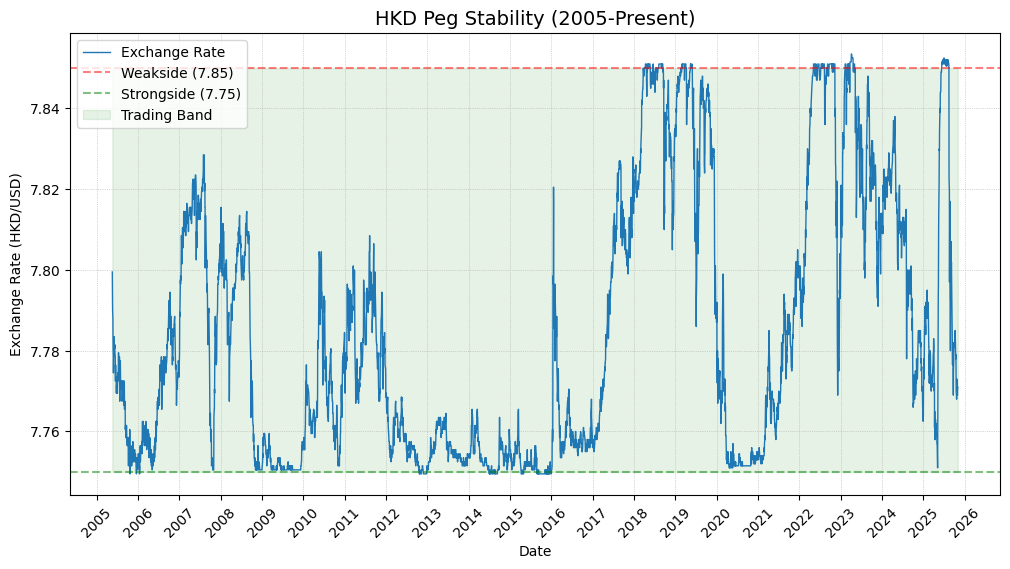

In [178]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(df.index, df["usd"], label="Exchange Rate", linewidth = 1)

ax1.axhline(7.85, color = "red", linestyle ="--", label = "Weakside (7.85)", alpha = 0.5)
ax1.axhline(7.75, color = "green", linestyle = "--", label = "Strongside (7.75)", alpha = 0.5)
ax1.fill_between(df.index, 7.75, 7.85, alpha=0.1, color='green', label='Trading Band')

ax1.set_title("HKD Peg Stability (2005-Present)", fontsize=14)
ax1.set_ylabel("Exchange Rate (HKD/USD)")
ax1.set_xlabel("Date")

ax1.legend(loc="upper left")

ax1.xaxis.set_major_locator(mdates.YearLocator(1))
plt.xticks(rotation=45)
plt.grid(linestyle=':', linewidth=0.5)
plt.savefig('../images/1_peg_stability.png', dpi=300)
plt.show()


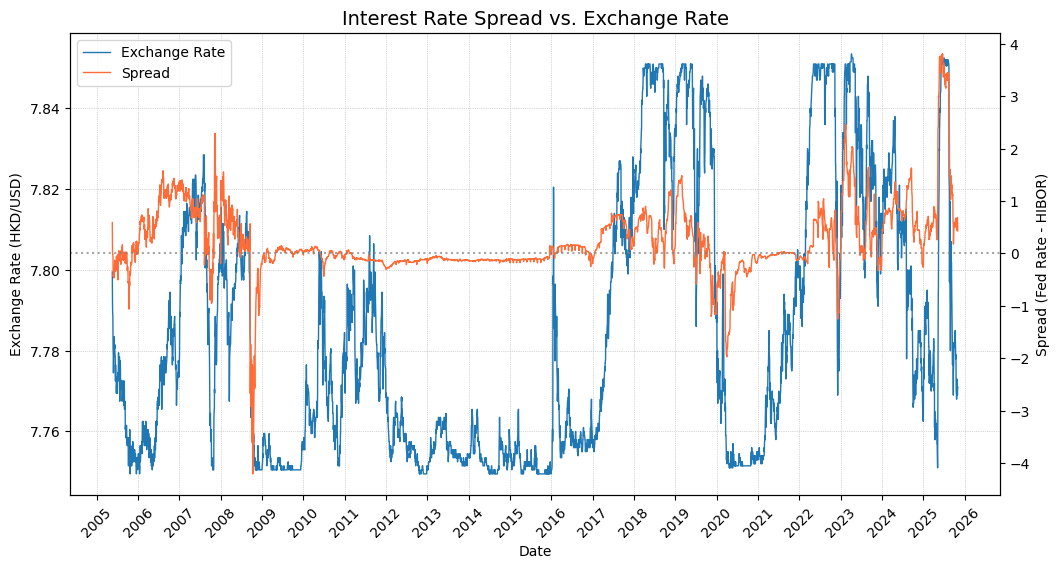

In [179]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax1 = plt.subplots(figsize=(12,6))

ax1.plot(df.index, df["usd"], label="Exchange Rate", linewidth = 1)
ax1.set_ylabel("Exchange Rate (HKD/USD)")
ax1.set_xlabel("Date")

ax1.xaxis.set_major_locator(mdates.YearLocator(1))
plt.xticks(rotation=45)

ax2 = ax1.twinx()
ax2.plot(df.index, df["spread"], label = "Spread", color="#FF6C37", linewidth = 1)
ax2.set_ylabel("Spread (Fed Rate - HIBOR)")
ax2.axhline(0, color='gray', linestyle=':', alpha=0.7)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2)

plt.title('Interest Rate Spread vs. Exchange Rate', fontsize=14)
ax1.grid(linestyle=':', linewidth=0.5)

plt.savefig('../images/2_spread_correlation.png', dpi=300)
plt.show()

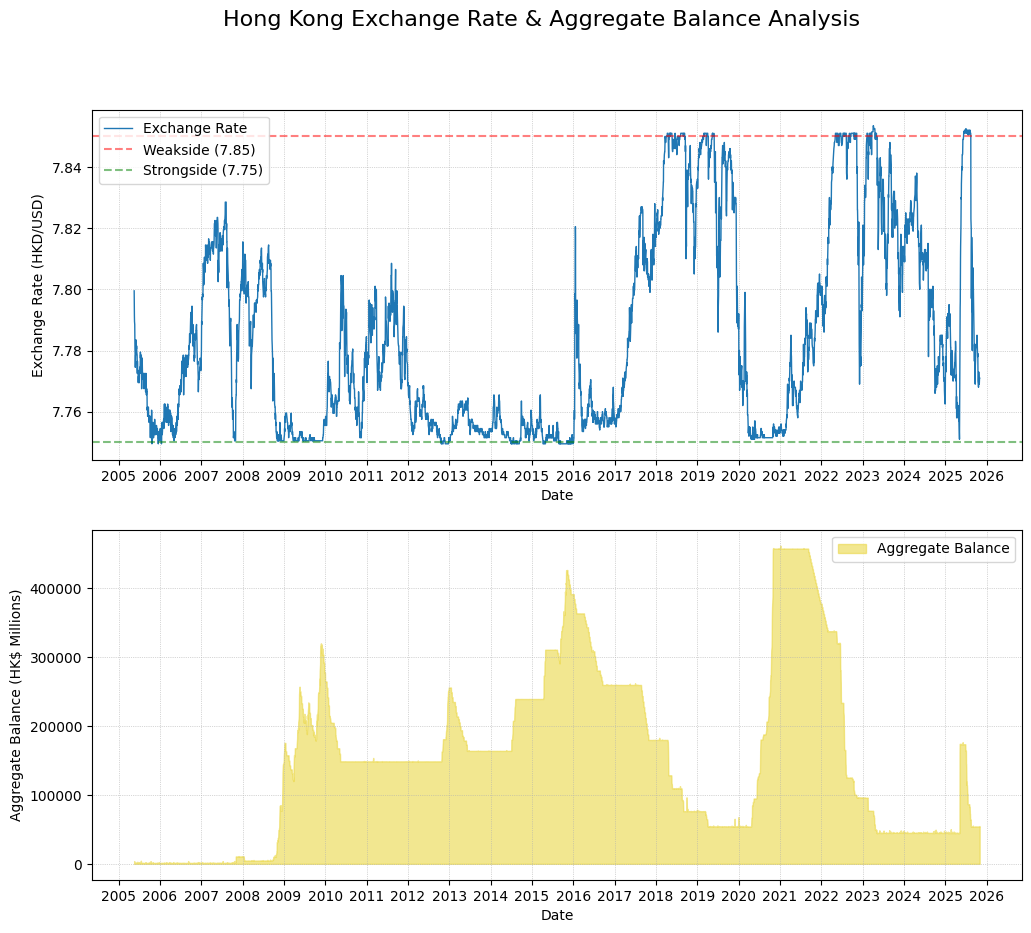

In [180]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axs = plt.subplots(2, 1, figsize=(12, 10))
ax1 = axs[0]
ax2 = axs[1]

ax1.plot(df.index, df["usd"], label="Exchange Rate", linewidth = 1)
ax1.set_ylabel("Exchange Rate (HKD/USD)")
ax1.axhline(7.85, color = "red", linestyle ="--", label = "Weakside (7.85)", alpha = 0.5)
ax1.axhline(7.75, color = "green", linestyle = "--", label = "Strongside (7.75)", alpha = 0.5)
ax1.set_xlabel("Date")

ax2.fill_between(df.index, df["closing_balance"], color="#ead746", alpha=0.6, label="Aggregate Balance")
ax2.set_ylabel("Aggregate Balance (HK$ Millions)")
ax2.set_xlabel("Date")

ax1.xaxis.set_major_locator(mdates.YearLocator(1))
ax2.xaxis.set_major_locator(mdates.YearLocator(1))

ax1.legend()
ax2.legend()
fig.suptitle("Hong Kong Exchange Rate & Aggregate Balance Analysis", fontsize=16)
ax1.grid(linestyle=':', linewidth=0.5)
ax2.grid(linestyle=':', linewidth=0.5)
plt.savefig('../images/3_intervention_mechanic.png', dpi=300)
plt.show()


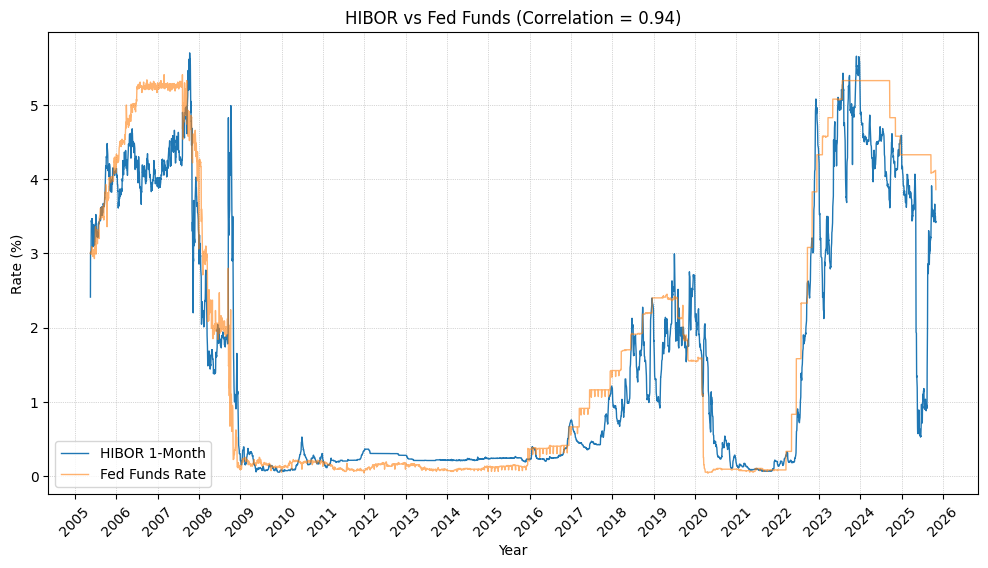

In [181]:
import matplotlib.pyplot as plt

fig,ax1 = plt.subplots(figsize=(12, 6))
plt.plot(df.index, df['hibor'], label='HIBOR 1-Month', linewidth=1)
plt.plot(df.index, df["fund_rate"], label='Fed Funds Rate', linewidth=1, alpha=0.6)
plt.ylabel('Rate (%)')
plt.xlabel('Year')
plt.legend()

ax1.xaxis.set_major_locator(mdates.YearLocator(1))
plt.xticks(rotation=45)
plt.grid(linestyle=':', linewidth=0.5)

corr = df["hibor"].corr(df["fund_rate"])
plt.title(f"HIBOR vs Fed Funds (Correlation = {corr:.2f})")
plt.savefig('../images/4_rate_correlation.png', dpi=300)
plt.show()
